In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt

transform = transforms.ToTensor()

train_dataset = datasets.MNIST(
    root='./data',
    train=True,
    download=True,
    transform=transform
)

test_dataset = datasets.MNIST(
    root='./data',
    train=False,
    download=True,
    transform=transform
)

train_loader = DataLoader(
    train_dataset,
    batch_size=128,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=128,
    shuffle=False
)

class Autoencoder(nn.Module):

    def __init__(self):
        super(Autoencoder, self).__init__()

        self.encoder = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 128),
            nn.ReLU(),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, 32)
        )

        self.decoder = nn.Sequential(
            nn.Linear(32, 64),
            nn.ReLU(),
            nn.Linear(64, 128),
            nn.ReLU(),
            nn.Linear(128, 784),
            nn.Sigmoid(),
           nn.Unflatten(1, (1, 28, 28))
        )

    def forward(self, x):
        encoded = self.encoder(x)
        decoded = self.decoder(encoded)
        return decoded

model = Autoencoder()

criterion = nn.MSELoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

num_epochs = 5

for epoch in range(num_epochs):

    running_loss = 0.0

    for data, _ in train_loader:

        output = model(data)

        loss = criterion(output, data)

        optimizer.zero_grad()

        loss.backward()

        optimizer.step()

        running_loss += loss.item()

    epoch_loss = running_loss / len(train_loader)

    print(
        f"Epoch [{epoch + 1}/{num_epochs}], "
        f"Loss: {epoch_loss:.6f}"
    )



Epoch [1/5], Loss: 0.059170
Epoch [2/5], Loss: 0.030064
Epoch [3/5], Loss: 0.023753
Epoch [4/5], Loss: 0.020708
Epoch [5/5], Loss: 0.018547


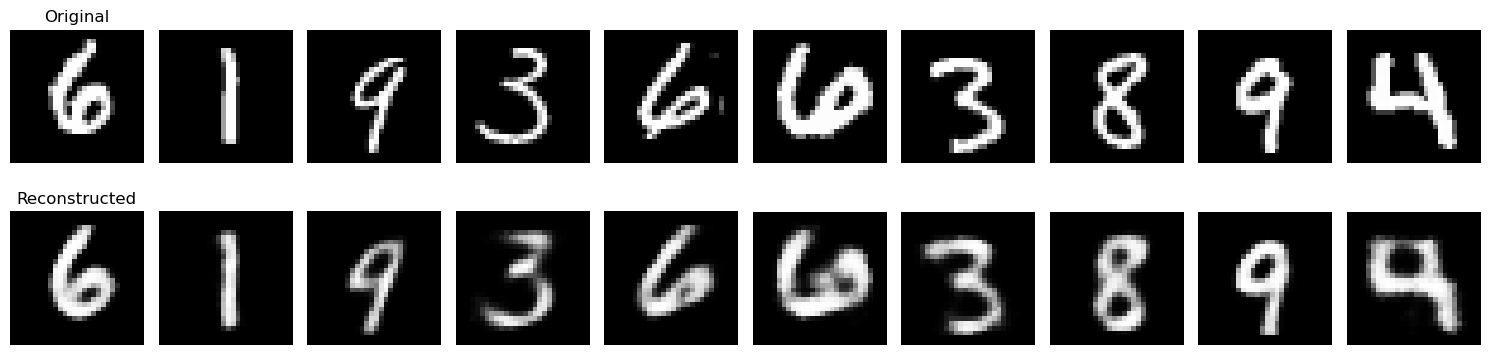

In [2]:
test_loader_small = DataLoader(
    test_dataset,
    batch_size=10,
    shuffle=True
)

images, _ = next(iter(test_loader_small))

with torch.no_grad():
    reconstructed = model(images)

fig, axes = plt.subplots(2, 10, figsize=(15, 4))

for i in range(10):

    axes[0, i].imshow(
        images[i].squeeze(),
        cmap='gray'
    )
    axes[0, i].axis('off')

    axes[1, i].imshow(
        reconstructed[i].squeeze(),
        cmap='gray'
    )
    axes[1, i].axis('off')

axes[0, 0].set_title("Original")
axes[1, 0].set_title("Reconstructed")

plt.tight_layout()
plt.show()